In [ ]:
# 라이브러리 임포트 및 데이터 수집
import pandas as pd
import numpy as np

#! pip install pybaseball -q
from pybaseball import statcast
from sklearn.linear_model import LogisticRegression

# 분석에 사용할 Statcast 데이터 수집
df_raw = statcast(start_dt='2025-03-18', end_dt='2025-09-28')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 426.1/426.1 kB 23.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 449.7/449.7 kB 32.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 63.1 MB/s eta 0:00:00
This is a large query, it may take a moment to complete


/usr/local/lib/python3.12/dist-packages/pybaseball/statcast.py:50: UserWarning: 
That's a nice request you got there. It'd be a shame if something were to happen to it.
We strongly recommend that you enable caching before running this. It's as simple as `pybaseball.cache.enable()`.
Since the Statcast requests can take a *really* long time to run, if something were to happen, like: a disconnect;
gremlins; computer repair by associates of Rudy Giuliani; electromagnetic interference from metal trash cans; etc.;
you could lose a lot of progress. Enabling caching will allow you to immediately recover all the successful
subqueries if that happens.
  warnings.warn(_OVERSIZE_WARNING)
  0%|          | 0/195 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_co

### **Phase1: 전이확률 및 기대득점 행렬 생성**

In [ ]:
# PA 단위 데이터 생성
raw = df_raw.copy()
raw = raw.sort_values(['game_pk', 'at_bat_number', 'pitch_number']).copy()

# PA 식별자
pa_id = ['game_pk', 'at_bat_number']

In [ ]:
# 각 PA의 진짜 첫 row에서 시작 상태 생성
pa_start = (
    raw
    .drop_duplicates(subset=pa_id, keep='first')
    .copy()
)

pa_start = pa_start[[
    'game_pk',
    'at_bat_number',
    'outs_when_up',
    'on_1b',
    'on_2b',
    'on_3b'
]].copy()

pa_start['start_outs'] = pa_start['outs_when_up'].astype(int)

pa_start['start_bases'] = (
    pa_start['on_1b'].notna().astype(int).astype(str)
    + pa_start['on_2b'].notna().astype(int).astype(str)
    + pa_start['on_3b'].notna().astype(int).astype(str)
)

pa_start = pa_start[[
    'game_pk',
    'at_bat_number',
    'start_outs',
    'start_bases'
]].copy()

In [ ]:
# 각 PA의 결과 행 생성
pa_result = (
    raw
    .dropna(subset=['events'])
    .sort_values(['game_pk', 'at_bat_number', 'pitch_number'])
    .drop_duplicates(subset=pa_id, keep='last')
    .copy()
)

pa_all = pa_result[[
    'game_pk',
    'game_date',
    'inning',
    'inning_topbot',
    'at_bat_number',
    'batter',
    'player_name',
    'events',
    'bat_score',
    'post_bat_score'
]].copy()

# 시작 상태 병합
pa_all = pa_all.merge(
    pa_start,
    on=['game_pk', 'at_bat_number'],
    how='left'
)

# 이번 PA에서 발생한 득점
pa_all['runs_on_play'] = pa_all['post_bat_score'] - pa_all['bat_score']

In [ ]:
# Event class 매핑
def map_event_class(event):
    if event in ['walk', 'hit_by_pitch']:
        return 'BB_HBP'
    elif event == 'single':
        return 'SINGLE'
    elif event == 'double':
        return 'DOUBLE'
    elif event == 'triple':
        return 'TRIPLE'
    elif event == 'home_run':
        return 'HOME_RUN'
    elif event == 'strikeout':
        return 'STRIKEOUT'
    elif event == 'grounded_into_double_play':
        return 'GIDP'
    elif event in [
        'field_out',
        'force_out',
        'fielders_choice_out',
        'fielders_choice',
        'double_play',
        'triple_play',
        'sac_fly',
        'sac_fly_double_play',
        'strikeout_double_play'
    ]:
        return 'BIP_OUT'
    else:
        return 'EXCLUDED'


pa_all['event_class'] = pa_all['events'].apply(map_event_class)

In [ ]:
# 모든 이벤트 기준으로 end_state 생성
pa_all['offense_id'] = (
    pa_all['game_pk'].astype(str)
    + '_'
    + pa_all['inning'].astype(str)
    + '_'
    + pa_all['inning_topbot'].astype(str)
)

pa_all = pa_all.sort_values(['game_pk', 'at_bat_number']).copy()

pa_all['end_outs'] = (
    pa_all
    .groupby('offense_id')['start_outs']
    .shift(-1)
    .fillna(3)
    .astype(int)
)

pa_all['end_bases'] = (
    pa_all
    .groupby('offense_id')['start_bases']
    .shift(-1)
    .fillna('000')
)

# 모델에 사용할 PA만 유지
pa = pa_all[pa_all['event_class'] != 'EXCLUDED'].copy()

In [ ]:
# 전이확률표 생성
transition_counts = (
    pa
    .groupby([
        'start_outs',
        'start_bases',
        'event_class',
        'runs_on_play',
        'end_outs',
        'end_bases'
    ])
    .size()
    .reset_index(name='n')
)

# 조건별 전체 표본 수 계산
transition_counts['total'] = (
    transition_counts
    .groupby(['start_outs', 'start_bases', 'event_class'])['n']
    .transform('sum')
)

# 전이확률 계산
transition_counts['prob'] = transition_counts['n'] / transition_counts['total']

In [ ]:
# 특정 조건의 전이분포 확인
def show_transition(start_outs, start_bases, event_class, top_n=20):
    result = (
        transition_counts[
            (transition_counts['start_outs'] == start_outs) &
            (transition_counts['start_bases'] == start_bases) &
            (transition_counts['event_class'] == event_class)
        ]
        .sort_values('prob', ascending=False)
        .head(top_n)
        .copy()
    )

    result['prob'] = result['prob'].round(4)

    return result[[
        'start_outs',
        'start_bases',
        'event_class',
        'runs_on_play',
        'end_outs',
        'end_bases',
        'n',
        'total',
        'prob'
    ]]

# 검수 코드
show_transition(0, '000', 'SINGLE')

,start_outs,start_bases,event_class,runs_on_play,end_outs,end_bases,n,total,prob
11,0,000,SINGLE,0,0,100,6428,6558,0.9802
10,0,000,SINGLE,0,0,010,64,6558,0.0098
12,0,000,SINGLE,0,1,000,59,6558,0.0090
9,0,000,SINGLE,0,0,001,6,6558,0.0009
13,0,000,SINGLE,1,3,000,1,6558,0.0002


In [ ]:
# 이닝 종료 시점의 공격팀 점수 계산
inning_end_score = (
    pa_all
    .groupby('offense_id')['post_bat_score']
    .last()
    .reset_index(name='inning_end_score')
)

# PA별 이닝 종료 점수 병합
pa_re = pa_all.merge(
    inning_end_score,
    on='offense_id',
    how='left'
)

# 해당 PA 시작 시점부터 이닝 종료까지의 득점
pa_re['runs_to_end_inning'] = pa_re['inning_end_score'] - pa_re['bat_score']

pa_re.head()

,game_pk,game_date,inning,inning_topbot,at_bat_number,batter,player_name,events,bat_score,post_bat_score,start_outs,start_bases,runs_on_play,event_class,offense_id,end_outs,end_bases,inning_end_score,runs_to_end_inning
0,776135,2025-09-28,1,Top,1,805904,"Aldegheri, Sam",strikeout,0,0,0,000,0,STRIKEOUT,776135_1_Top,1,000,1,1
1,776135,2025-09-28,1,Top,2,643289,"Aldegheri, Sam",single,0,0,1,000,0,SINGLE,776135_1_Top,1,100,1,1
2,776135,2025-09-28,1,Top,3,605170,"Aldegheri, Sam",hit_by_pitch,0,0,1,100,0,BB_HBP,776135_1_Top,1,110,1,1
3,776135,2025-09-28,1,Top,4,673237,"Aldegheri, Sam",single,0,1,1,110,1,SINGLE,776135_1_Top,1,101,1,1
4,776135,2025-09-28,1,Top,5,660821,"Aldegheri, Sam",strikeout,1,1,1,101,0,STRIKEOUT,776135_1_Top,2,101,1,0


In [ ]:
# Run Expectancy 테이블 생성
re_table = (
    pa_re
    .groupby(['start_outs', 'start_bases'])['runs_to_end_inning']
    .mean()
    .reset_index(name='RE')
)

re_table['RE'] = re_table['RE'].round(4)

re_table = re_table.sort_values(['start_outs', 'start_bases']).reset_index(drop=True)

re_table

,start_outs,start_bases,RE
0,0,000,0.4984
1,0,001,1.2789
2,0,010,1.1184
3,0,011,1.9751
4,0,100,0.8894
5,0,101,1.7897
6,0,110,1.5741
7,0,111,2.41
8,1,000,0.2658
9,1,001,0.8917


### **Phase2: wOBA 추정 및 각 EVENT 발생 확률 계산**

In [ ]:
# 2025 FanGraphs wOBA weights
WOBA_WEIGHTS = {
    'walk': 0.691,
    'hit_by_pitch': 0.722,
    'single': 0.882,
    'double': 1.252,
    'triple': 1.584,
    'home_run': 2.037
}

# PA별 wOBA numerator / denominator 생성
def get_woba_value(event):
    return WOBA_WEIGHTS.get(event, 0)


def get_woba_denom(event):
    # FanGraphs denominator: AB + BB - IBB + SF + HBP
    if event in ['intent_walk', 'catcher_interf', 'truncated_pa']:
        return 0
    elif event in ['sac_bunt', 'sac_bunt_double_play']:
        return 0
    else:
        return 1


pa_all['woba_value'] = pa_all['events'].apply(get_woba_value)
pa_all['woba_denom'] = pa_all['events'].apply(get_woba_denom)

In [ ]:
# 타자별 추정 wOBA 계산
batter_woba = (
    pa_all
    .groupby('batter')
    .agg(
        woba_num=('woba_value', 'sum'),
        woba_denom=('woba_denom', 'sum')
    )
    .reset_index()
)

batter_woba['woba_est'] = batter_woba['woba_num'] / batter_woba['woba_denom']
batter_woba = batter_woba.dropna(subset=['woba_est']).copy()

batter_woba.head()

,batter,woba_num,woba_denom,woba_est
0,455117,43.226,164,0.263573
1,456781,56.129,193,0.290824
2,457705,169.562,556,0.304968
3,457759,52.922,196,0.270010
4,467793,138.936,488,0.284705


In [ ]:
# 리그 평균 추정 wOBA 확인
league_woba_est = pa_all['woba_value'].sum() / pa_all['woba_denom'].sum()

league_woba_est

np.float64(0.31332780295587315)

In [ ]:
# Event class 목록
EVENT_CLASSES = [
    'BB_HBP',
    'SINGLE',
    'DOUBLE',
    'TRIPLE',
    'HOME_RUN',
    'STRIKEOUT',
    'BIP_OUT',
    'GIDP'
]

# 타자별 event_class count 생성
batter_event_counts = (
    pa
    .groupby(['batter', 'event_class'])
    .size()
    .reset_index(name='count')
)

# 모든 타자 x 모든 event_class 조합 생성
batters = pa[['batter']].drop_duplicates()
event_grid = pd.DataFrame({'event_class': EVENT_CLASSES})

batter_event_profile = batters.merge(event_grid, how='cross')

batter_event_profile = batter_event_profile.merge(
    batter_event_counts,
    on=['batter', 'event_class'],
    how='left'
)

batter_event_profile['count'] = batter_event_profile['count'].fillna(0)

In [ ]:
# 타자별 모델 PA 수 계산
batter_model_pa = (
    pa
    .groupby('batter')
    .size()
    .reset_index(name='model_pa')
)

# 타자별 wOBA와 event profile 병합
batter_event_profile = batter_event_profile.merge(
    batter_model_pa,
    on='batter',
    how='left'
)

batter_event_profile = batter_event_profile.merge(
    batter_woba[['batter', 'woba_est', 'woba_denom']],
    on='batter',
    how='left'
)

batter_event_profile = batter_event_profile.dropna(subset=['woba_est']).copy()

batter_event_profile.head()

,batter,event_class,count,model_pa,woba_est,woba_denom
0,805904,BB_HBP,5.0,52,0.373058,52
1,805904,SINGLE,6.0,52,0.373058,52
2,805904,DOUBLE,2.0,52,0.373058,52
3,805904,TRIPLE,0.0,52,0.373058,52
4,805904,HOME_RUN,4.0,52,0.373058,52


In [ ]:
# target wOBA 기준 event profile 생성
def get_event_probs_from_woba(target_woba, bandwidth=0.025, min_pa=300):
    data = batter_event_profile[
        batter_event_profile['woba_denom'] >= min_pa
    ].copy()

    data['woba_weight'] = np.exp(
        -0.5 * ((data['woba_est'] - target_woba) / bandwidth) ** 2
    )

    data['weighted_count'] = data['count'] * data['woba_weight']

    event_probs = (
        data
        .groupby('event_class')['weighted_count']
        .sum()
        .reset_index()
    )

    event_probs = event_grid.merge(
        event_probs,
        on='event_class',
        how='left'
    )

    event_probs['weighted_count'] = event_probs['weighted_count'].fillna(0)
    event_probs['prob'] = event_probs['weighted_count'] / event_probs['weighted_count'].sum()

    return event_probs[['event_class', 'prob']]

In [ ]:
# 예시: wOBA .340 타자의 event profile
get_event_probs_from_woba(0.340)

,event_class,prob
0,BB_HBP,0.097451
1,SINGLE,0.149164
2,DOUBLE,0.045590
3,TRIPLE,0.003779
4,HOME_RUN,0.035809
5,STRIKEOUT,0.209581
6,BIP_OUT,0.441172
7,GIDP,0.017454


In [ ]:
# transition branch에 end_state RE 붙이기
transition_ev = transition_counts.merge(
    re_table.rename(columns={
        'start_outs': 'end_outs',
        'start_bases': 'end_bases',
        'RE': 'end_RE'
    }),
    on=['end_outs', 'end_bases'],
    how='left'
)

# 이닝 종료 상태는 RE = 0
transition_ev['end_RE'] = transition_ev['end_RE'].fillna(0)

# branch별 기대값
transition_ev['branch_ev'] = transition_ev['runs_on_play'] + transition_ev['end_RE']

transition_ev.head()

,start_outs,start_bases,event_class,runs_on_play,end_outs,end_bases,n,total,prob,end_RE,branch_ev
0,0,000,BB_HBP,0,0,010,4,4077,0.000981,1.1184,1.1184
1,0,000,BB_HBP,0,0,100,4069,4077,0.998038,0.8894,0.8894
2,0,000,BB_HBP,0,1,000,4,4077,0.000981,0.2658,0.2658
3,0,000,BIP_OUT,0,1,000,21486,21486,1.000000,0.2658,0.2658
4,0,000,DOUBLE,0,0,001,14,2047,0.006839,1.2789,1.2789


In [ ]:
# start_state + event_class별 event 발생 후 기대득점
event_state_ev = (
    transition_ev
    .assign(weighted_ev=transition_ev['prob'] * transition_ev['branch_ev'])
    .groupby(['start_outs', 'start_bases', 'event_class'])['weighted_ev']
    .sum()
    .reset_index(name='event_ev')
)

event_state_ev.head()

,start_outs,start_bases,event_class,event_ev
0,0,000,BB_HBP,0.889013
1,0,000,BIP_OUT,0.2658
2,0,000,DOUBLE,1.116166
3,0,000,HOME_RUN,1.495289
4,0,000,SINGLE,0.886398


In [ ]:
# 특정 wOBA 타자의 특정 state 강공 기대득점 계산
def calc_swing_ev_from_woba(target_woba, start_outs, start_bases, bandwidth=0.015, min_pa=300):
    event_probs = get_event_probs_from_woba(
        target_woba=target_woba,
        bandwidth=bandwidth,
        min_pa=min_pa
    )

    state_ev = event_state_ev[
        (event_state_ev['start_outs'] == start_outs) &
        (event_state_ev['start_bases'] == start_bases)
    ].copy()

    result = event_probs.merge(
        state_ev,
        on='event_class',
        how='left'
    )

    result['event_ev'] = result['event_ev'].fillna(0)
    result['weighted_ev'] = result['prob'] * result['event_ev']

    swing_ev = result['weighted_ev'].sum()

    return swing_ev

In [ ]:
# 예시: wOBA .340 타자가 무사 1루에서 강공할 때 기대득점
calc_swing_ev_from_woba(
    target_woba=0.340,
    start_outs=0,
    start_bases='100'
)

np.float64(0.9428082416263074)

In [ ]:
# 강공 EV 계산 상세 확인
def show_swing_ev_detail(target_woba, start_outs, start_bases, bandwidth=0.015, min_pa=300):
    event_probs = get_event_probs_from_woba(
        target_woba=target_woba,
        bandwidth=bandwidth,
        min_pa=min_pa
    )

    state_ev = event_state_ev[
        (event_state_ev['start_outs'] == start_outs) &
        (event_state_ev['start_bases'] == start_bases)
    ].copy()

    result = event_probs.merge(
        state_ev,
        on='event_class',
        how='left'
    )

    result['event_ev'] = result['event_ev'].fillna(0)
    result['weighted_ev'] = result['prob'] * result['event_ev']

    result['prob'] = result['prob'].round(4)
    result['event_ev'] = result['event_ev'].round(4)
    result['weighted_ev'] = result['weighted_ev'].round(4)

    return result.sort_values('weighted_ev', ascending=False)

In [ ]:
# 상세 확인
show_swing_ev_detail(
    target_woba=0.340,
    start_outs=0,
    start_bases='100'
)

,event_class,prob,start_outs,start_bases,event_ev,weighted_ev
6,BIP_OUT,0.4362,0,100,0.5595,0.2441
1,SINGLE,0.1493,0,100,1.6098,0.2404
0,BB_HBP,0.0993,0,100,1.5529,0.1543
5,STRIKEOUT,0.2112,0,100,0.5296,0.1119
4,HOME_RUN,0.0371,0,100,2.4685,0.0915
2,DOUBLE,0.0456,0,100,1.9829,0.0905
3,TRIPLE,0.0038,0,100,2.1981,0.0084
7,GIDP,0.0173,0,100,0.1034,0.0018


In [ ]:
# Score Probability 테이블 생성
score_prob_table = (
    pa_re
    .assign(scored=(pa_re['runs_to_end_inning'] > 0).astype(int))
    .groupby(['start_outs', 'start_bases'])['scored']
    .mean()
    .reset_index(name='score_prob')
)

score_prob_table = score_prob_table.sort_values(['start_outs', 'start_bases']).reset_index(drop=True)

score_prob_table

,start_outs,start_bases,score_prob
0,0,000,0.270362
1,0,001,0.826531
2,0,010,0.599166
3,0,011,0.847247
4,0,100,0.411887
5,0,101,0.843299
6,0,110,0.627077
7,0,111,0.865900
8,1,000,0.159759
9,1,001,0.632696


In [ ]:
# transition branch에 end_state score probability 붙이기
transition_sp = transition_counts.merge(
    score_prob_table.rename(columns={
        'start_outs': 'end_outs',
        'start_bases': 'end_bases',
        'score_prob': 'end_score_prob'
    }),
    on=['end_outs', 'end_bases'],
    how='left'
)

# 이닝 종료 상태는 득점 확률 0
transition_sp['end_score_prob'] = transition_sp['end_score_prob'].fillna(0)

# branch별 득점 확률
# 해당 play에서 이미 득점하면 score probability = 1
# 득점하지 않았다면 end_state의 score probability 사용
transition_sp['branch_score_prob'] = np.where(
    transition_sp['runs_on_play'] > 0,
    1,
    transition_sp['end_score_prob']
)

transition_sp.head()

,start_outs,start_bases,event_class,runs_on_play,end_outs,end_bases,n,total,prob,end_score_prob,branch_score_prob
0,0,000,BB_HBP,0,0,010,4,4077,0.000981,0.599166,0.599166
1,0,000,BB_HBP,0,0,100,4069,4077,0.998038,0.411887,0.411887
2,0,000,BB_HBP,0,1,000,4,4077,0.000981,0.159759,0.159759
3,0,000,BIP_OUT,0,1,000,21486,21486,1.000000,0.159759,0.159759
4,0,000,DOUBLE,0,0,001,14,2047,0.006839,0.826531,0.826531


In [ ]:
# start_state + event_class별 득점 확률
event_state_sp = (
    transition_sp
    .assign(weighted_sp=transition_sp['prob'] * transition_sp['branch_score_prob'])
    .groupby(['start_outs', 'start_bases', 'event_class'])['weighted_sp']
    .sum()
    .reset_index(name='event_score_prob')
)

event_state_sp.head()

,start_outs,start_bases,event_class,event_score_prob
0,0,000,BB_HBP,0.411823
1,0,000,BIP_OUT,0.159759
2,0,000,DOUBLE,0.599003
3,0,000,HOME_RUN,1.000000
4,0,000,SINGLE,0.411915


In [ ]:
# 특정 wOBA 타자의 특정 state 강공 득점 확률 계산
def calc_swing_score_prob_from_woba(target_woba, start_outs, start_bases, bandwidth=0.015, min_pa=300):
    event_probs = get_event_probs_from_woba(
        target_woba=target_woba,
        bandwidth=bandwidth,
        min_pa=min_pa
    )

    state_sp = event_state_sp[
        (event_state_sp['start_outs'] == start_outs) &
        (event_state_sp['start_bases'] == start_bases)
    ].copy()

    result = event_probs.merge(
        state_sp,
        on='event_class',
        how='left'
    )

    result['event_score_prob'] = result['event_score_prob'].fillna(0)
    result['weighted_score_prob'] = result['prob'] * result['event_score_prob']

    return result['weighted_score_prob'].sum()

In [ ]:
# 예시: wOBA .340 타자가 무사 1루에서 강공할 때 득점 확률
calc_swing_score_prob_from_woba(
    target_woba=0.340,
    start_outs=0,
    start_bases='100'
)

np.float64(0.434368752053259)

### **Phase 3: 강공 VS 번트 비교**

In [ ]:
# 강공 vs 번트 비교: 기대득점 + 득점확률
def compare_swing_vs_bunt(current_woba, next_woba, bandwidth=0.015, min_pa=300):
    swing_ev = calc_swing_ev_from_woba(
        target_woba=current_woba,
        start_outs=0,
        start_bases='100',
        bandwidth=bandwidth,
        min_pa=min_pa
    )

    bunt_ev = calc_swing_ev_from_woba(
        target_woba=next_woba,
        start_outs=1,
        start_bases='010',
        bandwidth=bandwidth,
        min_pa=min_pa
    )

    swing_score_prob = calc_swing_score_prob_from_woba(
        target_woba=current_woba,
        start_outs=0,
        start_bases='100',
        bandwidth=bandwidth,
        min_pa=min_pa
    )

    bunt_score_prob = calc_swing_score_prob_from_woba(
        target_woba=next_woba,
        start_outs=1,
        start_bases='010',
        bandwidth=bandwidth,
        min_pa=min_pa
    )

    result = pd.DataFrame([{
        'current_woba': current_woba,
        'next_woba': next_woba,
        'swing_ev': swing_ev,
        'bunt_ev': bunt_ev,
        'ev_diff_swing_minus_bunt': swing_ev - bunt_ev,
        'swing_score_prob': swing_score_prob,
        'bunt_score_prob': bunt_score_prob,
        'score_prob_diff_swing_minus_bunt': swing_score_prob - bunt_score_prob
    }])

    return result

In [ ]:
compare_swing_vs_bunt(
    current_woba=0.299,
    next_woba=0.480
)

,current_woba,next_woba,swing_ev,bunt_ev,ev_diff_swing_minus_bunt,swing_score_prob,bunt_score_prob,score_prob_diff_swing_minus_bunt
0,0.299,0.48,0.904256,0.775306,0.12895,0.420544,0.436143,-0.0156


In [ ]:
# wOBA grid 생성
woba_grid = np.round(np.arange(0.200, 0.500, 0.002), 3)

# current_woba x next_woba 조합별 비교 결과 계산
heatmap_rows = []

for current_woba in woba_grid:
    for next_woba in woba_grid:
        result = compare_swing_vs_bunt(
            current_woba=current_woba,
            next_woba=next_woba,
            bandwidth=0.015,
            min_pa=300
        ).iloc[0]

        heatmap_rows.append({
            'current_woba': current_woba,
            'next_woba': next_woba,
            'ev_diff': result['ev_diff_swing_minus_bunt'],
            'score_prob_diff': result['score_prob_diff_swing_minus_bunt']
        })

heatmap_df = pd.DataFrame(heatmap_rows)

heatmap_df.head()

,current_woba,next_woba,ev_diff,score_prob_diff
0,0.2,0.200,0.264318,0.038238
1,0.2,0.202,0.264144,0.038130
2,0.2,0.204,0.263942,0.038007
3,0.2,0.206,0.263709,0.037865
4,0.2,0.208,0.263438,0.037703


In [ ]:
# 히트맵용 pivot table 생성
ev_matrix = heatmap_df.pivot(
    index='next_woba',
    columns='current_woba',
    values='ev_diff'
)

score_prob_matrix = heatmap_df.pivot(
    index='next_woba',
    columns='current_woba',
    values='score_prob_diff'
)

ev_matrix.head()

current_woba,0.200,0.202,0.204,0.206,0.208,0.210,0.212,0.214,0.216,0.218,...,0.480,0.482,0.484,0.486,0.488,0.490,0.492,0.494,0.496,0.498
next_woba,,,,,,,,,,,,,,,,,,,,,
0.200,0.264318,0.264485,0.264680,0.264905,0.265165,0.265467,0.265817,0.266220,0.266685,0.267218,...,0.487012,0.487027,0.487038,0.487045,0.487050,0.487053,0.487056,0.487058,0.487059,0.487060
0.202,0.264144,0.264311,0.264506,0.264731,0.264991,0.265293,0.265643,0.266046,0.266511,0.267044,...,0.486838,0.486853,0.486864,0.486871,0.486876,0.486879,0.486882,0.486884,0.486885,0.486886
0.204,0.263942,0.264110,0.264304,0.264529,0.264790,0.265092,0.265441,0.265845,0.266309,0.266843,...,0.486637,0.486652,0.486662,0.486669,0.486674,0.486678,0.486680,0.486682,0.486683,0.486684
0.206,0.263709,0.263876,0.264071,0.264296,0.264556,0.264858,0.265208,0.265611,0.266076,0.266609,...,0.486403,0.486418,0.486428,0.486436,0.486441,0.486444,0.486447,0.486449,0.486450,0.486451
0.208,0.263438,0.263606,0.263800,0.264025,0.264286,0.264588,0.264937,0.265341,0.265805,0.266339,...,0.486133,0.486148,0.486158,0.486165,0.486170,0.486174,0.486176,0.486178,0.486179,0.486180


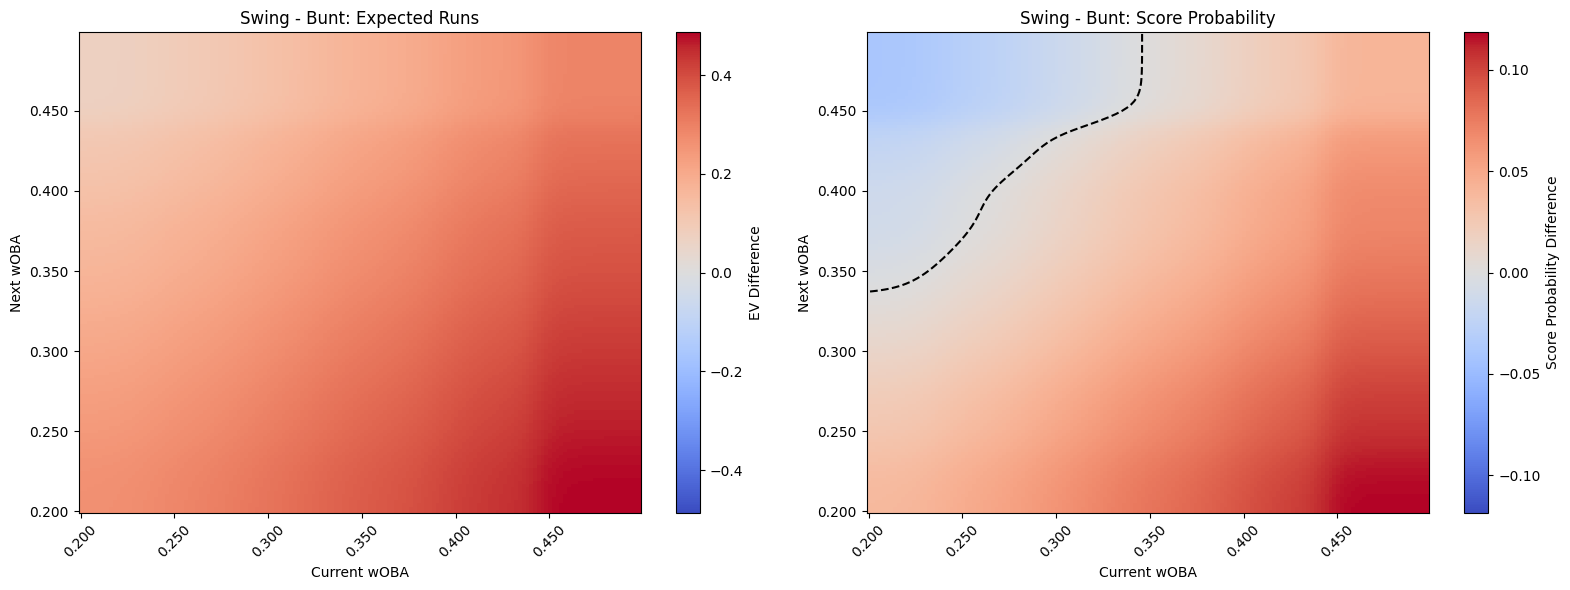

In [ ]:
# 히트맵 시각화
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 색상 범위 대칭 설정
ev_abs_max = np.abs(ev_matrix.values).max()
sp_abs_max = np.abs(score_prob_matrix.values).max()

# 좌표축용 index
x_pos = np.arange(len(ev_matrix.columns))
y_pos = np.arange(len(ev_matrix.index))

# 0.050 단위 tick 설정
x_tick_idx = [
    i for i, x in enumerate(ev_matrix.columns)
    if np.isclose((x * 1000) % 50, 0)
]

y_tick_idx = [
    i for i, y in enumerate(ev_matrix.index)
    if np.isclose((y * 1000) % 50, 0)
]

# 기대득점 차이 heatmap
im1 = axes[0].imshow(
    ev_matrix.values,
    origin='lower',
    aspect='auto',
    cmap='coolwarm',
    vmin=-ev_abs_max,
    vmax=ev_abs_max
)

# 0 경계선(점선)
axes[0].contour(
    x_pos,
    y_pos,
    ev_matrix.values,
    levels=[0],
    colors='black',
    linewidths=1.5,
    linestyles='dashed'
)

axes[0].set_title('Swing - Bunt: Expected Runs')
axes[0].set_xlabel('Current wOBA')
axes[0].set_ylabel('Next wOBA')

axes[0].set_xticks(x_tick_idx)
axes[0].set_xticklabels([f'{ev_matrix.columns[i]:.3f}' for i in x_tick_idx], rotation=45)

axes[0].set_yticks(y_tick_idx)
axes[0].set_yticklabels([f'{ev_matrix.index[i]:.3f}' for i in y_tick_idx])

cbar1 = plt.colorbar(im1, ax=axes[0])
cbar1.set_label('EV Difference')

# 득점확률 차이 heatmap
im2 = axes[1].imshow(
    score_prob_matrix.values,
    origin='lower',
    aspect='auto',
    cmap='coolwarm',
    vmin=-sp_abs_max,
    vmax=sp_abs_max
)

# 0 경계선(점선)
axes[1].contour(
    x_pos,
    y_pos,
    score_prob_matrix.values,
    levels=[0],
    colors='black',
    linewidths=1.5,
    linestyles='dashed'
)

axes[1].set_title('Swing - Bunt: Score Probability')
axes[1].set_xlabel('Current wOBA')
axes[1].set_ylabel('Next wOBA')

axes[1].set_xticks(x_tick_idx)
axes[1].set_xticklabels([f'{score_prob_matrix.columns[i]:.3f}' for i in x_tick_idx], rotation=45)

axes[1].set_yticks(y_tick_idx)
axes[1].set_yticklabels([f'{score_prob_matrix.index[i]:.3f}' for i in y_tick_idx])

cbar2 = plt.colorbar(im2, ax=axes[1])
cbar2.set_label('Score Probability Difference')

plt.tight_layout()
plt.show()